## Domain Adaptation

Usually, you can fine-tune a pretrained model directly on your task data.

If your data uses specialized language, such as legal or scientific text, first continue training the model on that type of text. This helps it learn the domain’s vocabulary and writing style.

This step is called **domain adaptation**. Afterward, fine-tune the model for your specific task.

In [84]:
CHECKPOINT = "distilbert/distilbert-base-uncased"

Although BERT and RoBERTa models are widely used, this example uses **DistilBERT**, a smaller model that trains faster while often retaining similar performance on downstream tasks.

DistilBERT was created using **knowledge distillation**: a larger “teacher” model, such as BERT, guides the training of a smaller “student” model. The details of this technique are beyond this section.

In [85]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)
model = AutoModelForMaskedLM.from_pretrained(CHECKPOINT)

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 896.34it/s]


In [86]:
model.num_parameters()

66985530

In [87]:
text = 'This is a great [MASK]'

In [88]:
import torch

In [89]:
inputs = tokenizer(text, return_tensors='pt')
token_logits = model(**inputs).logits

In [90]:
mask_token_index = torch.where(inputs['input_ids'] == tokenizer.mask_token_id)[1]
mask_token_logits = token_logits[0, mask_token_index, :]
top_5_tokens = torch.topk(mask_token_logits, 5, dim=1).indices[0].tolist()

In [91]:
for token in top_5_tokens:
    print(f"> {text.replace(tokenizer.mask_token, tokenizer.decode([token]))}")

> This is a great !
> This is a great .
> This is a great deal
> This is a great adventure
> This is a great ;


In [92]:
from datasets import load_dataset

In [93]:
imdb_dataset = load_dataset("stanfordnlp/imdb")
imdb_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [94]:
sample = imdb_dataset['train'].shuffle(seed=42).select(range(3))

In [95]:
for row in sample:
    print(f"\n'>>> Review: {row['text']}'")
    print(f"'>>> Label: {row['label']}'")


'>>> Review: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it's the language, or the spirit, but I think this series is more English than American. By the way, the actors are really good and funny. The acting is not superficial at all...'
'>>> Label: 1'

'>>> Review: This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bunch of kids called "when you stu

In [96]:
for split in ["train", "test", "unsupervised"]:
    print(split, set(imdb_dataset[split]["label"]))

train {0, 1}
test {0, 1}
unsupervised {-1}


In [97]:
def tokenize_function(examples):
    results = tokenizer(
        examples["text"],
        return_offsets_mapping=True,
    )

    if tokenizer.is_fast:
        results["word_ids"] = [
            results.word_ids(i)
            for i in range(len(results["input_ids"]))
        ]

    return results


In [98]:
tokenized_dataset = imdb_dataset.map(tokenize_function, batched=True, remove_columns=['text', 'label'])

Map: 100%|██████████| 50000/50000 [00:45<00:00, 1101.81 examples/s]


In [99]:
chunk_size = 128

Note that using a small chunk size can be detrimental in real-world scenarios, so you should use a size that corresponds to the use case you will apply your model to.

In [100]:
tokenized_samples = tokenized_dataset["train"][:3]

for idx, sample in enumerate(tokenized_samples["input_ids"]):
    print(f"'>>> Review {idx} length: {len(sample)}'")

'>>> Review 0 length: 363'
'>>> Review 1 length: 304'
'>>> Review 2 length: 133'


In [101]:
def group_texts(examples):
    concatenated_examples = {k: sum(examples[k], []) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // chunk_size) * chunk_size
    result = {
        k: [t[i : i + chunk_size] for i in range(0, total_length, chunk_size)]
        for k, t in concatenated_examples.items()
    }

    result["labels"] = result["input_ids"].copy()
    return result

In [102]:
lm_datasets = tokenized_dataset.map(group_texts, batched=True)
lm_datasets

Map: 100%|██████████| 50000/50000 [04:34<00:00, 182.30 examples/s]


DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'word_ids', 'labels'],
        num_rows: 61291
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'word_ids', 'labels'],
        num_rows: 59904
    })
    unsupervised: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'word_ids', 'labels'],
        num_rows: 122957
    })
})

In [103]:
tokenizer.decode(lm_datasets["train"][1]["input_ids"])

"as the vietnam war and race issues in the united states. in between asking politicians and ordinary denizens of stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men. < br / > < br / > what kills me about i am curious - yellow is that 40 years ago, this was considered pornographic. really, the sex and nudity scenes are few and far between, even then it ' s not shot like some cheaply made porno. while my countrymen mind find it shocking, in reality sex and nudity are a major staple in swedish cinema. even ingmar bergman,"

In [104]:
from transformers import DataCollatorForWholeWordMask

In [105]:
data_collator = DataCollatorForWholeWordMask(tokenizer=tokenizer, mlm_probability=0.15)

In [106]:
samples = [lm_datasets["train"][i] for i in range(2)]
for sample in samples:
    _ = sample.pop("word_ids")

for chunk in data_collator(samples)["input_ids"]:
    print(f"\n'>>> {tokenizer.decode(chunk)}'")


'>>> [CLS] i rented i am curious - yellow from my video store because of all the controversy that surrounded it when it [MASK] first released in 1967. i also heard that at first it was seized by u. s. customs if it ever tried to [MASK] this [MASK] [MASK] therefore being a fan of [MASK] considered " controversial " i really had to see this for myself. < br [MASK] [MASK] [MASK] [MASK] / > the plot is centered around a [MASK] swedish drama student named lena who [MASK] to learn everything she [MASK] about life. in particular she [MASK] to [MASK] her attentions to [MASK] some sort of [MASK] on what the average swede thought about certaincule issues such'

'>>> as the [MASK] war and race loyal [MASK] the united states. in [MASK] asking politicians and ordinary denizens of stockholm [MASK] their [MASK] on politics, she has sex with [MASK] drama teacher, classmates, and married men. < br / > < br / [MASK] [MASK] kills me about i am curious - yellow is that 40 years ago, this was considered p

In [107]:
train_size = 10000
test_size = int(train_size * 0.1)

downsampled_dataset = lm_datasets['train'].train_test_split(
    train_size=train_size, test_size=test_size, seed=42
)

In [108]:
downsampled_dataset

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'word_ids', 'labels'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'word_ids', 'labels'],
        num_rows: 1000
    })
})

In [109]:
from huggingface_hub import notebook_login

notebook_login()

In [113]:
downsampled_dataset = downsampled_dataset.remove_columns(["word_ids", "token_type_ids"])

In [117]:
from transformers import TrainingArguments, Trainer

batch_size = 64
logging_steps = len(downsampled_dataset['train']) // batch_size
model_name = CHECKPOINT.split('/')[-1]

train_args = TrainingArguments(
    output_dir=f'{model_name}-finetuned-imdb',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    weight_decay=0.01,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    push_to_hub=True,
    fp16=True,
    logging_steps=logging_steps,
    remove_unused_columns=False
)

In [120]:
trainer = Trainer(
    model=model,
    args=train_args,
    train_dataset=downsampled_dataset['train'],
    eval_dataset=downsampled_dataset['test'],
    data_collator=data_collator,
    processing_class=tokenizer
)

In [121]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,2.946827,2.986442
2,2.960838,2.990637
3,3.025832,2.993025


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.08it/s]


TrainOutput(global_step=471, training_loss=2.978501896949331, metrics={'train_runtime': 127.8227, 'train_samples_per_second': 234.7, 'train_steps_per_second': 3.685, 'total_flos': 994208670720000.0, 'train_loss': 2.978501896949331, 'epoch': 3.0})

In [122]:
import math

In [123]:
eval_results = trainer.evaluate()
print(f">>> Perplexity: {math.exp(eval_results['eval_loss']):.2f}")

Training Loss,Validation Loss,Epoch
3.025832,3.024738,3


>>> Perplexity: 20.59


## A custom training loop with 🤗 Accelerate

The `Trainer` hides the training loop. Here we write it ourselves with plain PyTorch, plus 🤗 Accelerate for device placement, mixed precision, gradient accumulation and multi-GPU support.

We **continue from the last checkpoint** the `Trainer` saved (`checkpoint-471`, i.e. after 3 epochs) and train it for a few more epochs.

One thing to fix first: `trainer.evaluate()` masks the evaluation set with **new random masks on every call**, so the perplexity it reports changes from run to run. For a fair comparison between epochs, we apply the masking **once** to the evaluation set and reuse those fixed masks.

In [124]:
from transformers import DataCollatorForWholeWordMask, default_data_collator

eval_masking_collator = DataCollatorForWholeWordMask(tokenizer=tokenizer, mlm_probability=0.15, seed=42)


def insert_random_mask(batch):
    features = [dict(zip(batch, values)) for values in zip(*batch.values())]
    masked_inputs = eval_masking_collator(features)  # also drops "offset_mapping"
    return {"masked_" + k: v.numpy() for k, v in masked_inputs.items()}


eval_dataset = downsampled_dataset["test"].map(
    insert_random_mask,
    batched=True,
    remove_columns=downsampled_dataset["test"].column_names,
)
eval_dataset = eval_dataset.rename_columns(
    {
        "masked_input_ids": "input_ids",
        "masked_attention_mask": "attention_mask",
        "masked_labels": "labels",
    }
)
eval_dataset

C:\Users\user\Desktop\MlLibraries\.venv\Lib\site-packages\transformers\data\data_collator.py:1030: FutureWarning: DataCollatorForWholeWordMask is deprecated and will be removed in a future version, you can now use DataCollatorForLanguageModeling with whole_word_mask=True instead.
  warnings.warn(
Map: 100%|██████████| 1000/1000 [00:01<00:00, 554.78 examples/s]


Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 1000
})

In [125]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    downsampled_dataset["train"],
    shuffle=True,
    batch_size=batch_size,
    collate_fn=data_collator,  # random whole-word masking, new masks every epoch
)
eval_dataloader = DataLoader(
    eval_dataset,
    batch_size=batch_size,
    collate_fn=default_data_collator,  # masks are already in the dataset
)

Load the weights from the last checkpoint the `Trainer` wrote. We also free the in-memory `Trainer` and its model so the GPU only holds one copy.

In [126]:
import gc
from transformers.trainer_utils import get_last_checkpoint

last_checkpoint = get_last_checkpoint(train_args.output_dir)
print(f">>> Resuming from: {last_checkpoint}")

for name in ("trainer", "model"):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForMaskedLM.from_pretrained(last_checkpoint)

>>> Resuming from: distilbert-base-uncased-finetuned-imdb\checkpoint-471


Loading weights: 100%|██████████| 105/105 [00:00<00:00, 725.10it/s]


### Optimizer, Accelerator and learning-rate scheduler

As with the `Trainer`, we use AdamW with weight decay 0.01. Bias and LayerNorm weights are excluded from weight decay.

In [127]:
from torch.optim import AdamW

learning_rate = 2e-5
weight_decay = 0.01
no_decay = ["bias", "LayerNorm.weight"]

optimizer_grouped_parameters = [
    {
        "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
        "weight_decay": weight_decay,
    },
    {
        "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
        "weight_decay": 0.0,
    },
]
optimizer = AdamW(optimizer_grouped_parameters, lr=learning_rate)

In [128]:
from accelerate import Accelerator
from accelerate.utils import set_seed

set_seed(42)

gradient_accumulation_steps = 1  # effective batch size = batch_size * this * num_processes

# Use the same mixed_precision as the Trainer above: Accelerate keeps one shared state per process
accelerator = Accelerator(
    mixed_precision="fp16" if torch.cuda.is_available() else "no",
    gradient_accumulation_steps=gradient_accumulation_steps,
)

model, optimizer, train_dataloader, eval_dataloader = accelerator.prepare(
    model, optimizer, train_dataloader, eval_dataloader
)
print(f">>> device: {accelerator.device} | mixed precision: {accelerator.mixed_precision} | processes: {accelerator.num_processes}")

>>> device: cuda | mixed precision: fp16 | processes: 1


Create the scheduler **after** `accelerator.prepare()`. On several GPUs the dataloader gets sharded, so `len(train_dataloader)` is the number of batches per process.

In [129]:
from transformers import get_scheduler

num_train_epochs = 3
num_update_steps_per_epoch = math.ceil(len(train_dataloader) / gradient_accumulation_steps)
num_training_steps = num_train_epochs * num_update_steps_per_epoch
num_warmup_steps = int(0.06 * num_training_steps)

lr_scheduler = get_scheduler(
    "linear",
    optimizer=optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=num_training_steps,
)
print(f">>> {num_training_steps} optimization steps ({num_warmup_steps} warmup)")

>>> 471 optimization steps (28 warmup)


### Evaluation metrics

For every masked token in the (fixed) evaluation set we compute:

- **loss**: cross-entropy, averaged over *all masked tokens*. This is token-weighted, not a mean of per-batch averages, so the last smaller batch does not skew it.
- **perplexity**: $\exp(\text{loss})$.
- **accuracy**: how often the top prediction is the original token.
- **top-5 accuracy**: how often the original token is among the 5 highest-scoring predictions.

The sums are kept **per example** and collected with `accelerator.gather_for_metrics`. On multiple GPUs this drops the duplicate samples Accelerate adds to even out the last batch, so the metrics stay exact.

In [130]:
import torch.nn.functional as F


def evaluate(model, dataloader):
    model.eval()
    totals = torch.zeros(4, device=accelerator.device)  # loss_sum, top1, top5, n_tokens

    for batch in dataloader:
        with torch.no_grad():
            logits = model(**batch).logits

        labels = batch["labels"]
        mask = labels != -100
        example_ids = mask.nonzero(as_tuple=True)[0]

        masked_logits = logits[mask].float()
        targets = labels[mask]
        token_loss = F.cross_entropy(masked_logits, targets, reduction="none")
        top5 = masked_logits.topk(5, dim=-1).indices
        top1_hit = (top5[:, 0] == targets).float()
        top5_hit = (top5 == targets.unsqueeze(-1)).any(dim=-1).float()

        per_example = torch.zeros(labels.shape[0], 4, device=logits.device)
        per_example.index_add_(
            0, example_ids, torch.stack([token_loss, top1_hit, top5_hit, torch.ones_like(token_loss)], dim=1)
        )
        totals += accelerator.gather_for_metrics(per_example).sum(dim=0)

    loss_sum, top1, top5, n_tokens = totals.tolist()
    loss = loss_sum / n_tokens
    return {
        "loss": loss,
        "perplexity": math.exp(loss) if loss < 100 else float("inf"),
        "accuracy": top1 / n_tokens,
        "top5_accuracy": top5 / n_tokens,
        "masked_tokens": int(n_tokens),
    }


def format_metrics(metrics):
    return (
        f"loss {metrics['loss']:.4f} | perplexity {metrics['perplexity']:.2f} | "
        f"acc {metrics['accuracy']:.2%} | top-5 acc {metrics['top5_accuracy']:.2%}"
    )

Score the checkpoint before training, so we have a baseline to compare against:

In [131]:
baseline_metrics = evaluate(model, eval_dataloader)
accelerator.print(f">>> Checkpoint (before training): {format_metrics(baseline_metrics)}")

>>> Checkpoint (before training): loss 2.9772 | perplexity 19.63 | acc 47.88% | top-5 acc 66.63%


### The training loop

At each step:
1. `accelerator.accumulate` skips gradient synchronisation and the optimizer step until `gradient_accumulation_steps` batches have been processed.
2. `accelerator.backward` scales the loss for fp16.
3. Gradients are clipped to a max norm of 1.0 (the `Trainer` default).
4. The LR scheduler only advances when the optimizer actually stepped. In fp16 the step is skipped if the gradients overflowed.

Every `logging_steps` we log the training loss, learning rate and gradient norm. After every epoch we evaluate, then:
- save the full training state (model, optimizer, scheduler, scaler, RNG) to `last_state/`, so the run can be resumed with `accelerator.load_state(...)`;
- save the model to `best/` whenever the evaluation loss improves.

In [132]:
import os
import time
from tqdm.auto import tqdm

output_dir = f"{model_name}-finetuned-imdb-accelerate"
best_model_dir = os.path.join(output_dir, "best")
state_dir = os.path.join(output_dir, "last_state")
max_grad_norm = 1.0
logging_steps = 20


def save_model(model, save_dir):
    accelerator.wait_for_everyone()
    unwrapped_model = accelerator.unwrap_model(model)
    unwrapped_model.save_pretrained(
        save_dir, is_main_process=accelerator.is_main_process, save_function=accelerator.save
    )
    if accelerator.is_main_process:
        tokenizer.save_pretrained(save_dir)


train_history = []  # one row every `logging_steps` optimizer steps
eval_history = [{"epoch": 0, "step": 0, "train_loss": None, **baseline_metrics}]
best_eval_loss = baseline_metrics["loss"]
best_epoch = 0

completed_steps = 0
running_loss = torch.zeros((), device=accelerator.device)
running_batches = 0
grad_norm = None
progress_bar = tqdm(range(num_training_steps), disable=not accelerator.is_local_main_process)

for epoch in range(1, num_train_epochs + 1):
    model.train()
    epoch_loss = torch.zeros((), device=accelerator.device)
    epoch_start = time.time()

    for batch in train_dataloader:
        with accelerator.accumulate(model):
            outputs = model(**batch)
            loss = outputs.loss
            accelerator.backward(loss)
            if accelerator.sync_gradients:
                grad_norm = accelerator.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            optimizer.zero_grad()

        running_loss += loss.detach()
        epoch_loss += loss.detach()
        running_batches += 1

        if accelerator.sync_gradients:
            if not accelerator.optimizer_step_was_skipped:
                lr_scheduler.step()
            completed_steps += 1
            progress_bar.update(1)

            if completed_steps % logging_steps == 0:
                avg_loss = accelerator.reduce(running_loss, reduction="mean").item() / running_batches
                log = {
                    "step": completed_steps,
                    "epoch": completed_steps / num_update_steps_per_epoch,
                    "train_loss": avg_loss,
                    "learning_rate": lr_scheduler.get_last_lr()[0],
                    "grad_norm": grad_norm.item() if grad_norm is not None else None,
                }
                train_history.append(log)
                progress_bar.set_postfix(loss=f"{avg_loss:.4f}", lr=f"{log['learning_rate']:.2e}")
                running_loss.zero_()
                running_batches = 0

    # ----- end of epoch: evaluate, checkpoint -----
    train_loss = accelerator.reduce(epoch_loss, reduction="mean").item() / len(train_dataloader)
    metrics = evaluate(model, eval_dataloader)
    eval_history.append({"epoch": epoch, "step": completed_steps, "train_loss": train_loss, **metrics})
    accelerator.print(
        f">>> Epoch {epoch}/{num_train_epochs} ({time.time() - epoch_start:.0f}s) | "
        f"train loss {train_loss:.4f} | eval {format_metrics(metrics)}"
    )

    accelerator.save_state(state_dir)
    if metrics["loss"] < best_eval_loss:
        best_eval_loss, best_epoch = metrics["loss"], epoch
        save_model(model, best_model_dir)
        accelerator.print(f"    new best model saved to {best_model_dir}")

progress_bar.close()
save_model(model, output_dir)  # final weights
accelerator.print(f">>> Done. Best epoch: {best_epoch} (eval loss {best_eval_loss:.4f})")

 33%|███▎      | 156/471 [00:41<01:18,  4.01it/s, loss=3.0325, lr=1.49e-05][RANK 0] Removed shared tensor {'vocab_projector.weight'} while saving. This should be OK, but check by verifying that you don't receive any warning while reloading


>>> Epoch 1/3 (42s) | train loss 3.0349 | eval loss 2.9644 | perplexity 19.38 | acc 47.98% | top-5 acc 66.73%



Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.73it/s]


    new best model saved to distilbert-base-uncased-finetuned-imdb-accelerate\best


 66%|██████▋   | 313/471 [01:26<00:41,  3.78it/s, loss=3.0226, lr=7.72e-06][RANK 0] Removed shared tensor {'vocab_projector.weight'} while saving. This should be OK, but check by verifying that you don't receive any warning while reloading


...

>>> Epoch 3/3 (46s) | train loss 2.9915 | eval loss 2.9381 | perplexity 18.88 | acc 48.48% | top-5 acc 67.03%



100%|██████████| 471/471 [02:20<00:00,  3.35it/s, loss=2.9889, lr=4.97e-07]


    new best model saved to distilbert-base-uncased-finetuned-imdb-accelerate\best


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.70it/s]

>>> Done. Best epoch: 3 (eval loss 2.9381)


### Results

All evaluation metrics, epoch by epoch (epoch 0 = the `Trainer` checkpoint we started from):

In [133]:
import pandas as pd

eval_df = pd.DataFrame(eval_history).set_index("epoch")
eval_df.style.format(
    {
        "train_loss": "{:.4f}",
        "loss": "{:.4f}",
        "perplexity": "{:.2f}",
        "accuracy": "{:.2%}",
        "top5_accuracy": "{:.2%}",
    },
    na_rep="-",
)

,step,train_loss,loss,perplexity,accuracy,top5_accuracy,masked_tokens
epoch,,,,,,,
0,0,-,2.9772,19.63,47.88%,66.63%,19080
1,157,3.0349,2.9644,19.38,47.98%,66.73%,19080
2,314,3.0010,2.9482,19.07,48.30%,66.90%,19080
3,471,2.9915,2.9381,18.88,48.48%,67.03%,19080


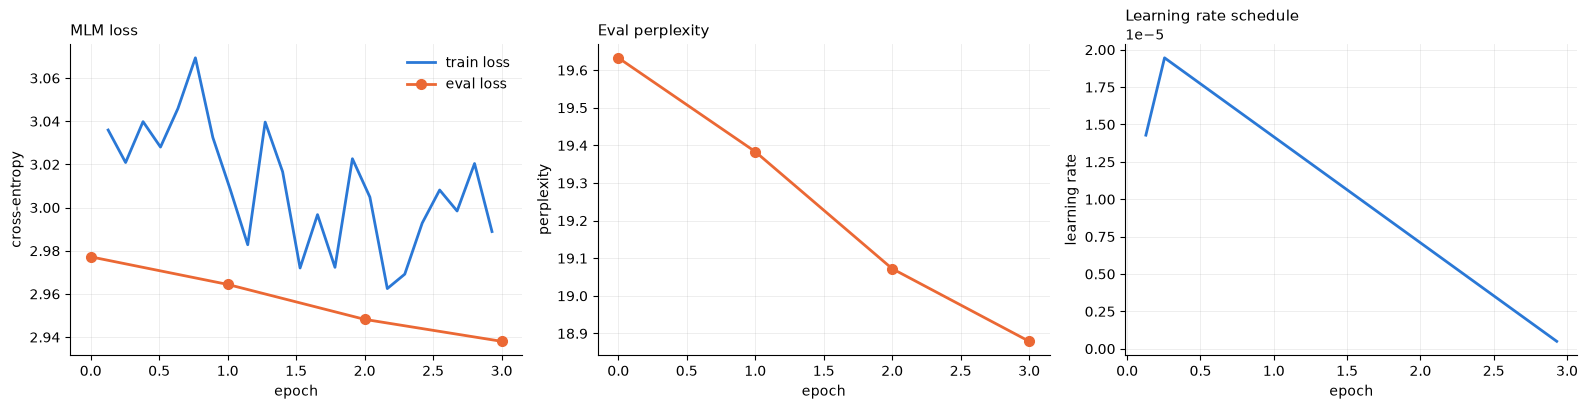

In [134]:
import matplotlib.pyplot as plt

train_df = pd.DataFrame(train_history)
TRAIN_COLOR, EVAL_COLOR = "#2a78d6", "#eb6834"

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))


def style(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)


ax = axes[0]
if not train_df.empty:
    ax.plot(train_df["epoch"], train_df["train_loss"], color=TRAIN_COLOR, linewidth=2, label="train loss")
ax.plot(eval_df.index, eval_df["loss"], color=EVAL_COLOR, linewidth=2, marker="o", markersize=7, label="eval loss")
style(ax, "MLM loss", "cross-entropy")
ax.legend(frameon=False)

ax = axes[1]
ax.plot(eval_df.index, eval_df["perplexity"], color=EVAL_COLOR, linewidth=2, marker="o", markersize=7)
style(ax, "Eval perplexity", "perplexity")

ax = axes[2]
if not train_df.empty:
    ax.plot(train_df["epoch"], train_df["learning_rate"], color=TRAIN_COLOR, linewidth=2)
style(ax, "Learning rate schedule", "learning rate")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

plt.tight_layout()
plt.show()

### Qualitative check

Compare the original pretrained DistilBERT with our domain-adapted model on the same sentence as at the start of the notebook. After adaptation, predictions should be more "movie-review"-like.

In [135]:
from transformers import pipeline

final_model_dir = best_model_dir if best_epoch > 0 else last_checkpoint
pipe_device = 0 if torch.cuda.is_available() else -1

fill_mask_base = pipeline("fill-mask", model=CHECKPOINT, device=pipe_device)
fill_mask_adapted = pipeline("fill-mask", model=final_model_dir, device=pipe_device)

for sentence in [text, "The acting in this [MASK] was terrible.", "I would give this film a [MASK] out of 10."]:
    print(f"\n>>> {sentence}")
    for label, pipe in [("base", fill_mask_base), ("adapted", fill_mask_adapted)]:
        preds = ", ".join(f"{p['token_str']} ({p['score']:.2f})" for p in pipe(sentence, top_k=5))
        print(f"    {label:>8}: {preds}")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 744.46it/s]



>>> This is a great [MASK]
        base: ! (0.40), . (0.10), deal (0.04), adventure (0.02), ; (0.01)
     adapted: ! (0.29), . (0.18), film (0.08), movie (0.05), deal (0.03)

>>> The acting in this [MASK] was terrible.
        base: movie (0.21), film (0.12), episode (0.08), production (0.04), drama (0.03)
     adapted: film (0.54), movie (0.35), episode (0.02), production (0.01), one (0.01)

>>> I would give this film a [MASK] out of 10.
        base: 7 (0.35), 9 (0.21), rating (0.07), 5 (0.06), 10 (0.06)
     adapted: 7 (0.40), 9 (0.17), 10 (0.13), 4 (0.09), 3 (0.08)


### (Optional) Push to the Hub

You are already logged in via `notebook_login()`. Set `PUSH_TO_HUB = True` to upload the best model and tokenizer to `<your-username>/distilbert-base-uncased-finetuned-imdb-accelerate`.

In [136]:
PUSH_TO_HUB = False

if PUSH_TO_HUB and accelerator.is_main_process:
    hub_model = AutoModelForMaskedLM.from_pretrained(final_model_dir)
    hub_model.push_to_hub(output_dir, commit_message=f"Accelerate training loop - best epoch {best_epoch}")
    tokenizer.push_to_hub(output_dir)